<a href="https://colab.research.google.com/github/DOHA-BASEM3/DS330-Deep-Learning-Project/blob/main/DS330_P1_Teletubbies%F0%9F%92%97.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Dataset Loading**

In [26]:
%pip install -q ucimlrepo

In [27]:

# Import libraries
import pandas as pd
import numpy as np

from ucimlrepo import fetch_ucirepo

# Load Combined Cycle Power Plant dataset
power_plant = fetch_ucirepo(id=294)

# Separate input features and target variable
X = power_plant.data.features.copy()
y = power_plant.data.targets.copy()

# Combine features and target for initial inspection
df = pd.concat([X, y], axis=1)

# Display dataset information
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nInput features:")
print(X.columns.tolist())

print("\nTarget variable:")
print(y.columns.tolist())

# Display first five rows
display(df.head())


Dataset loaded successfully!
Dataset shape: (9568, 5)

Input features:
['AT', 'V', 'AP', 'RH']

Target variable:
['PE']


,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


Data Quality Assessment and Descriptive Statistics

In [28]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

print("\nStatistical summary:")
display(df.describe())

Missing values:
AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

Duplicate rows:
41

Data types:
AT    float64
V     float64
AP    float64
RH    float64
PE    float64
dtype: object

Statistical summary:


,AT,V,AP,RH,PE
count,9568.000000,9568.000000,9568.000000,9568.000000,9568.000000
mean,19.651231,54.305804,1013.259078,73.308978,454.365009
std,7.452473,12.707893,5.938784,14.600269,17.066995
min,1.810000,25.360000,992.890000,25.560000,420.260000
25%,13.510000,41.740000,1009.100000,63.327500,439.750000
50%,20.345000,52.080000,1012.940000,74.975000,451.550000
75%,25.720000,66.540000,1017.260000,84.830000,468.430000
max,37.110000,81.560000,1033.300000,100.160000,495.760000


#Data Preprocessing

In [29]:
df = df.drop_duplicates().reset_index(drop=True)

X = df[['AT', 'V', 'AP', 'RH']].copy()
y = df[['PE']].copy()

print("Dataset shape after removing duplicates:", df.shape)
print("Remaining duplicate rows:", df.duplicated().sum())

Dataset shape after removing duplicates: (9527, 5)
Remaining duplicate rows: 0


# **Train / Validation / Test Split**

In [30]:

from sklearn.model_selection import train_test_split

# Split the dataset into training and temporary sets
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42
)

# Split the temporary set into validation and test sets
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42
)

# Display dataset split shapes
print("Training set:", X_train.shape, y_train.shape)
print("Validation set:", X_val.shape, y_val.shape)
print("Test set:", X_test.shape, y_test.shape)


Training set: (6668, 4) (6668, 1)
Validation set: (1429, 4) (1429, 1)
Test set: (1430, 4) (1430, 1)


# **Feature Standardization**

In [31]:

from sklearn.preprocessing import StandardScaler

# Initialize the scaler
scaler = StandardScaler()

# Fit on training data and transform all sets
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Display the shapes
print("Training set:", X_train_scaled.shape)
print("Validation set:", X_val_scaled.shape)
print("Test set:", X_test_scaled.shape)


Training set: (6668, 4)
Validation set: (1429, 4)
Test set: (1430, 4)


# **Linear Regression Baseline**

In [32]:

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

linear_model = LinearRegression()

linear_model.fit(X_train_scaled, y_train)

y_train_pred = linear_model.predict(X_train_scaled)
y_val_pred = linear_model.predict(X_val_scaled)

train_mse = mean_squared_error(y_train, y_train_pred)
val_mse = mean_squared_error(y_val, y_val_pred)

print("Linear Regression Results")
print("Training MSE:", train_mse)
print("Validation MSE:", val_mse)


Linear Regression Results
Training MSE: 20.27482223194883
Validation MSE: 21.439597193820646


# **Baseline Deep Neural Network**

Baseline Deep Neural Network Results
Training MSE: 16.7957
Validation MSE: 18.6084
Training Time: 29.47 seconds

Linear Regression Comparison
Linear Regression Validation MSE: 21.4396
Deep Neural Network Validation MSE: 18.6084
Improvement: 13.21%


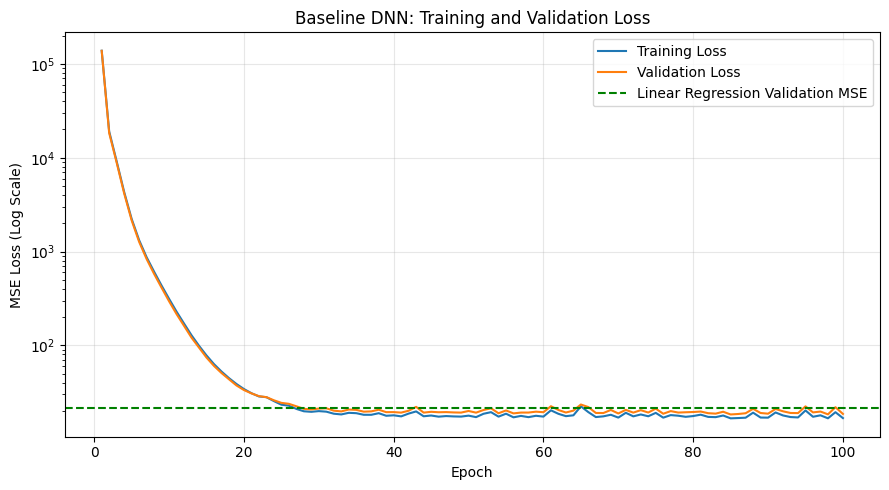

In [33]:

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import time

from torch.utils.data import TensorDataset, DataLoader

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cpu")

# Prepare tensors
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)

y_train_tensor = torch.tensor(
    y_train.to_numpy(), dtype=torch.float32
)
y_val_tensor = torch.tensor(
    y_val.to_numpy(), dtype=torch.float32
)

# Baseline hyperparameters
hidden_layers = [64, 32]
learning_rate = 0.001
batch_size = 32
epochs = 100

# Training data loader
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)

generator = torch.Generator().manual_seed(42)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    generator=generator
)

# Deep neural network
model = nn.Sequential(
    nn.Linear(4, hidden_layers[0]),
    nn.ReLU(),
    nn.Linear(hidden_layers[0], hidden_layers[1]),
    nn.ReLU(),
    nn.Linear(hidden_layers[1], 1)
).to(device)

# Loss function and optimizer
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=learning_rate
)

# Training
train_losses = []
val_losses = []

start_time = time.perf_counter()

for epoch in range(epochs):
    model.train()

    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()
        predictions = model(X_batch)
        loss = criterion(predictions, y_batch)
        loss.backward()
        optimizer.step()

    model.eval()

    with torch.no_grad():
        train_predictions = model(X_train_tensor.to(device))
        val_predictions = model(X_val_tensor.to(device))

        train_loss = criterion(
            train_predictions, y_train_tensor.to(device)
        ).item()

        val_loss = criterion(
            val_predictions, y_val_tensor.to(device)
        ).item()

    train_losses.append(train_loss)
    val_losses.append(val_loss)

training_time = time.perf_counter() - start_time

# Baseline results
nn_train_mse = train_losses[-1]
nn_val_mse = val_losses[-1]

print("Baseline Deep Neural Network Results")
print(f"Training MSE: {nn_train_mse:.4f}")
print(f"Validation MSE: {nn_val_mse:.4f}")
print(f"Training Time: {training_time:.2f} seconds")

print("\nLinear Regression Comparison")
print(f"Linear Regression Validation MSE: {val_mse:.4f}")
print(f"Deep Neural Network Validation MSE: {nn_val_mse:.4f}")

improvement = (val_mse - nn_val_mse) / val_mse * 100
print(f"Improvement: {improvement:.2f}%")

# Loss curves
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, epochs + 1),
    train_losses,
    label="Training Loss"
)

plt.plot(
    range(1, epochs + 1),
    val_losses,
    label="Validation Loss"
)

plt.axhline(
    y=val_mse,
    color="green",
    linestyle="--",
    label="Linear Regression Validation MSE"
)

plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss (Log Scale)")
plt.title("Baseline DNN: Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# **Hyperparameter Experiments**

## <font color="#3B82F6">Learning Rate</font>



### Learning Rate Experiment 1 — LR = 0.0001

In [42]:

def run_learning_rate_experiment(lr):
    torch.manual_seed(42)
    np.random.seed(42)

    generator = torch.Generator().manual_seed(42)

    loader = DataLoader(
        train_dataset,
        batch_size=32,
        shuffle=True,
        generator=generator
    )

    experiment_model = nn.Sequential(
        nn.Linear(4, 64),
        nn.ReLU(),
        nn.Linear(64, 32),
        nn.ReLU(),
        nn.Linear(32, 1)
    ).to(device)

    loss_fn = nn.MSELoss()
    experiment_optimizer = torch.optim.Adam(
        experiment_model.parameters(), lr=lr
    )

    training_losses = []
    validation_losses = []

    start_time = time.perf_counter()

    for epoch in range(100):
        experiment_model.train()

        for xb, yb in loader:
            xb = xb.to(device)
            yb = yb.to(device)

            experiment_optimizer.zero_grad()
            loss = loss_fn(experiment_model(xb), yb)
            loss.backward()
            experiment_optimizer.step()

        experiment_model.eval()

        with torch.no_grad():
            train_mse_epoch = loss_fn(
                experiment_model(X_train_tensor.to(device)),
                y_train_tensor.to(device)
            ).item()

            val_mse_epoch = loss_fn(
                experiment_model(X_val_tensor.to(device)),
                y_val_tensor.to(device)
            ).item()

        training_losses.append(train_mse_epoch)
        validation_losses.append(val_mse_epoch)

    elapsed = time.perf_counter() - start_time

    return {
        "Learning Rate": lr,
        "Train MSE": training_losses[-1],
        "Val MSE": validation_losses[-1],
        "Time (s)": elapsed,
        "Train Losses": training_losses,
        "Val Losses": validation_losses
    }


lr_results = []

result = run_learning_rate_experiment(0.0001)
lr_results.append(result)

print("Learning Rate:", result["Learning Rate"])
print(f"Training MSE: {result['Train MSE']:.4f}")
print(f"Validation MSE: {result['Val MSE']:.4f}")
print(f"Training Time: {result['Time (s)']:.2f} seconds")


Learning Rate: 0.0001
Training MSE: 31.7889
Validation MSE: 31.3234
Training Time: 28.99 seconds


### Learning Rate Experiment 2 — LR = 0.0003

In [43]:

result = run_learning_rate_experiment(0.0003)
lr_results.append(result)

print("Learning Rate:", result["Learning Rate"])
print(f"Training MSE: {result['Train MSE']:.4f}")
print(f"Validation MSE: {result['Val MSE']:.4f}")
print(f"Training Time: {result['Time (s)']:.2f} seconds")


Learning Rate: 0.0003
Training MSE: 17.4802
Validation MSE: 19.0203
Training Time: 28.95 seconds


### Learning Rate Experiment 3 — LR = 0.003

In [44]:

result = run_learning_rate_experiment(0.003)
lr_results.append(result)

print("Learning Rate:", result["Learning Rate"])
print(f"Training MSE: {result['Train MSE']:.4f}")
print(f"Validation MSE: {result['Val MSE']:.4f}")
print(f"Training Time: {result['Time (s)']:.2f} seconds")


Learning Rate: 0.003
Training MSE: 17.2582
Validation MSE: 19.1169
Training Time: 28.81 seconds


### Learning Rate Experiment 4 — LR = 0.01

In [45]:

result = run_learning_rate_experiment(0.01)
lr_results.append(result)

print("Learning Rate:", result["Learning Rate"])
print(f"Training MSE: {result['Train MSE']:.4f}")
print(f"Validation MSE: {result['Val MSE']:.4f}")
print(f"Training Time: {result['Time (s)']:.2f} seconds")


Learning Rate: 0.01
Training MSE: 21.0044
Validation MSE: 23.7329
Training Time: 31.00 seconds


### Learning Rate Experiment 5 — LR = 0.03

In [46]:

result = run_learning_rate_experiment(0.03)
lr_results.append(result)

print("Learning Rate:", result["Learning Rate"])
print(f"Training MSE: {result['Train MSE']:.4f}")
print(f"Validation MSE: {result['Val MSE']:.4f}")
print(f"Training Time: {result['Time (s)']:.2f} seconds")


Learning Rate: 0.03
Training MSE: 31.6638
Validation MSE: 35.6667
Training Time: 29.50 seconds


### Learning Rate Experiments — Results Summary

In [47]:

lr_table = pd.DataFrame([
    {
        "Run": "Baseline",
        "Learning Rate": 0.001,
        "Train MSE": nn_train_mse,
        "Val MSE": nn_val_mse,
        "Time (s)": training_time
    },
    *[
        {
            "Run": f"LR Experiment {i}",
            "Learning Rate": r["Learning Rate"],
            "Train MSE": r["Train MSE"],
            "Val MSE": r["Val MSE"],
            "Time (s)": r["Time (s)"]
        }
        for i, r in enumerate(lr_results, start=1)
    ]
])

display(lr_table.round(4))


,Run,Learning Rate,Train MSE,Val MSE,Time (s)
0,Baseline,0.0010,16.7957,18.6084,29.4717
1,LR Experiment 1,0.0001,31.7889,31.3234,28.9860
2,LR Experiment 2,0.0003,17.4802,19.0203,28.9541
3,LR Experiment 3,0.0030,17.2582,19.1169,28.8121
4,LR Experiment 4,0.0100,21.0044,23.7329,30.9952
5,LR Experiment 5,0.0300,31.6638,35.6667,29.5031


### Learning Rate — Loss Curves

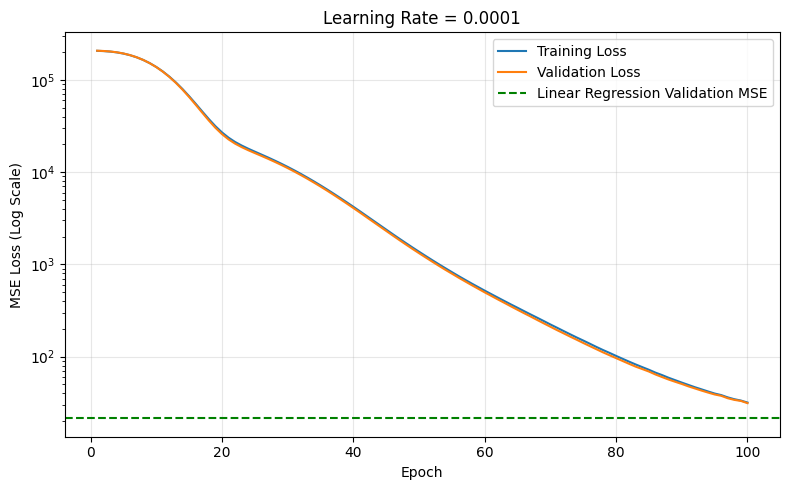

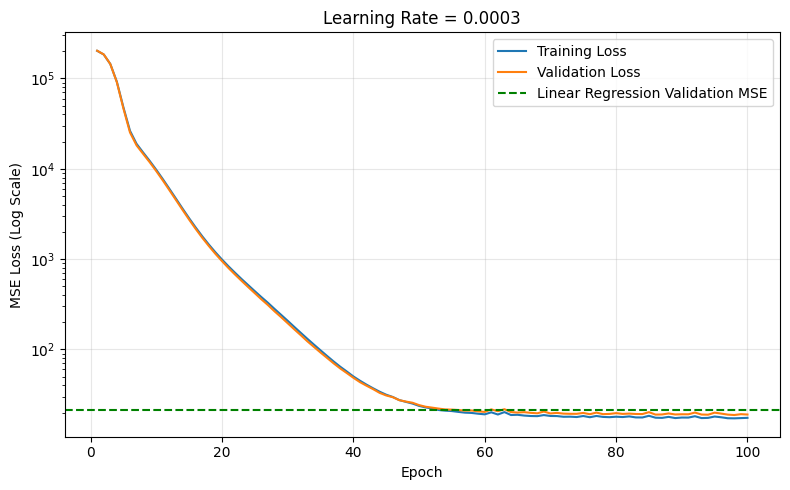

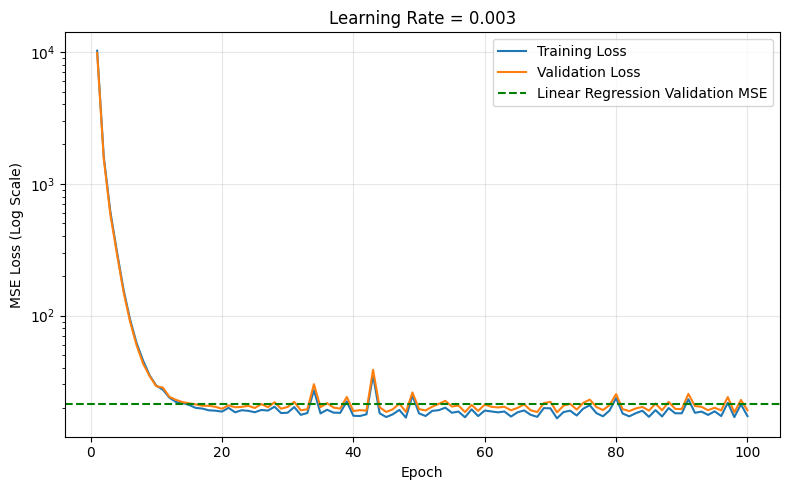

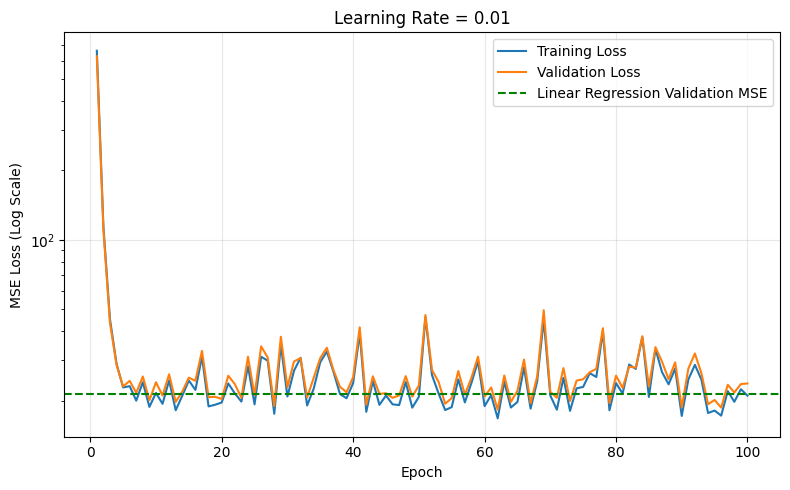

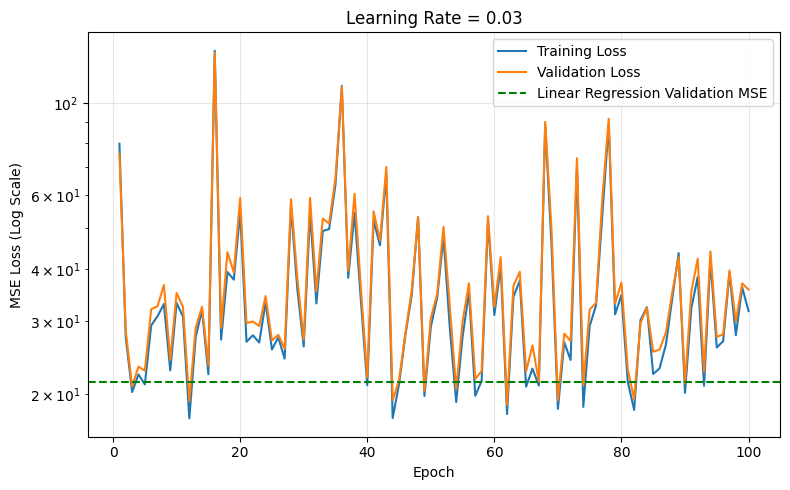

In [48]:

for r in lr_results:
    plt.figure(figsize=(8, 5))

    plt.plot(
        range(1, len(r["Train Losses"]) + 1),
        r["Train Losses"],
        label="Training Loss"
    )

    plt.plot(
        range(1, len(r["Val Losses"]) + 1),
        r["Val Losses"],
        label="Validation Loss"
    )

    plt.axhline(
        y=val_mse,
        color="green",
        linestyle="--",
        label="Linear Regression Validation MSE"
    )

    plt.yscale("log")
    plt.xlabel("Epoch")
    plt.ylabel("MSE Loss (Log Scale)")
    plt.title(f"Learning Rate = {r['Learning Rate']}")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


## <font color="#3B82F6">Optimizer </font>

### Optimizer Experiment 1 — SGD

In [58]:

def run_optimizer_experiment(optimizer_type, momentum=0.0, learning_rate=0.001):
    torch.manual_seed(42)
    np.random.seed(42)

    generator = torch.Generator().manual_seed(42)

    loader = DataLoader(
        train_dataset,
        batch_size=32,
        shuffle=True,
        generator=generator
    )

    experiment_model = nn.Sequential(
        nn.Linear(4, 64),
        nn.ReLU(),
        nn.Linear(64, 32),
        nn.ReLU(),
        nn.Linear(32, 1)
    ).to(device)

    criterion = nn.MSELoss()

    if optimizer_type == "SGD":
        experiment_optimizer = torch.optim.SGD(
            experiment_model.parameters(),
            lr=learning_rate,
            momentum=momentum
        )

    elif optimizer_type == "Adam":
        experiment_optimizer = torch.optim.Adam(
            experiment_model.parameters(),
            lr=learning_rate
        )

    else:
        raise ValueError("Unsupported optimizer")

    train_history = []
    val_history = []

    start_time = time.perf_counter()

    for epoch in range(100):
        experiment_model.train()

        for xb, yb in loader:
            xb = xb.to(device)
            yb = yb.to(device)

            experiment_optimizer.zero_grad()
            predictions = experiment_model(xb)
            loss = criterion(predictions, yb)

            loss.backward()
            experiment_optimizer.step()

        experiment_model.eval()

        with torch.no_grad():
            train_loss = criterion(
                experiment_model(X_train_tensor.to(device)),
                y_train_tensor.to(device)
            ).item()

            val_loss = criterion(
                experiment_model(X_val_tensor.to(device)),
                y_val_tensor.to(device)
            ).item()

        train_history.append(train_loss)
        val_history.append(val_loss)

    elapsed = time.perf_counter() - start_time

    return {
        "Optimizer": optimizer_type,
        "Momentum": momentum,
        "Learning Rate": learning_rate,
        "Train MSE": train_history[-1],
        "Val MSE": val_history[-1],
        "Time (s)": elapsed,
        "Train Losses": train_history,
        "Val Losses": val_history
    }


optimizer_results = []

result = run_optimizer_experiment(
    "SGD",
    momentum=0.0,
    learning_rate=0.001
)

optimizer_results.append(result)

print("Optimizer: SGD")
print(f"Learning Rate: {result['Learning Rate']}")
print(f"Training MSE: {result['Train MSE']:.4f}")
print(f"Validation MSE: {result['Val MSE']:.4f}")
print(f"Training Time: {result['Time (s)']:.2f} seconds")


Optimizer: SGD
Learning Rate: 0.001
Training MSE: nan
Validation MSE: nan
Training Time: 21.37 seconds


**Observation — SGD**

In this experiment, we tested SGD with a learning rate of 0.001 while keeping the other settings unchanged. Both training and validation MSE returned NaN, indicating that the model became numerically unstable during training. We believe this may be due to large weight updates, which prevented the model from converging. We kept this result to show that SGD was not stable with our current settings and to compare it with the other optimizers.

### Optimizer Experiment 2 — SGD with Momentum (0.9)

In [59]:

result = run_optimizer_experiment("SGD", momentum=0.9)
optimizer_results.append(result)

print("Optimizer: SGD with Momentum")
print("Momentum:", result["Momentum"])
print(f"Training MSE: {result['Train MSE']:.4f}")
print(f"Validation MSE: {result['Val MSE']:.4f}")
print(f"Training Time: {result['Time (s)']:.2f} seconds")


Optimizer: SGD with Momentum
Momentum: 0.9
Training MSE: nan
Validation MSE: nan
Training Time: 27.88 seconds


We tested SGD with a momentum value of 0.9 to see if it could improve training stability compared to standard SGD. We kept the learning rate at 0.001 and all other settings unchanged.

However, both training and validation MSE returned NaN, similar to our previous SGD experiment. We observed that adding momentum did not solve the numerical instability. We believe this may be caused by large weight updates during training.

We kept this result to document the unsuccessful experiment and compare it with other optimizers.

### Optimizer Experiment 3 — SGD Stability Test (LR = 0.00001)

In [60]:

torch.manual_seed(42)
np.random.seed(42)

generator = torch.Generator().manual_seed(42)

sgd_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    generator=generator
)

sgd_model = nn.Sequential(
    nn.Linear(4, 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 1)
).to(device)

sgd_optimizer = torch.optim.SGD(
    sgd_model.parameters(),
    lr=0.00001
)

sgd_criterion = nn.MSELoss()

sgd_train_losses = []
sgd_val_losses = []

start_time = time.perf_counter()

for epoch in range(100):
    sgd_model.train()

    for xb, yb in sgd_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        sgd_optimizer.zero_grad()
        loss = sgd_criterion(sgd_model(xb), yb)
        loss.backward()
        sgd_optimizer.step()

    sgd_model.eval()

    with torch.no_grad():
        train_loss = sgd_criterion(
            sgd_model(X_train_tensor.to(device)),
            y_train_tensor.to(device)
        ).item()

        val_loss = sgd_criterion(
            sgd_model(X_val_tensor.to(device)),
            y_val_tensor.to(device)
        ).item()

    sgd_train_losses.append(train_loss)
    sgd_val_losses.append(val_loss)

sgd_time = time.perf_counter() - start_time

print("SGD Stability Test")
print("Learning Rate: 0.00001")
print(f"Training MSE: {sgd_train_losses[-1]:.4f}")
print(f"Validation MSE: {sgd_val_losses[-1]:.4f}")
print(f"Training Time: {sgd_time:.2f} seconds")


SGD Stability Test
Learning Rate: 0.00001
Training MSE: 17.3211
Validation MSE: 18.8810
Training Time: 21.29 seconds


**Observation — SGD Stability Test**

In this experiment, we reduced the learning rate from 0.001 to 0.00001 while keeping SGD and all other settings unchanged.

Unlike our previous SGD experiment, the model completed training without producing NaN values. We obtained a training MSE of 17.3211 and a validation MSE of 18.8810.

From these results, we observed that reducing the learning rate improved numerical stability. This suggests that the original learning rate was too high for SGD under our current training settings.

### Optimizer Experiments — Results Summary

In [53]:

optimizer_table = pd.DataFrame([
    {
        "Experiment": "Baseline",
        "Optimizer": "Adam",
        "Learning Rate": 0.001,
        "Train MSE": nn_train_mse,
        "Val MSE": nn_val_mse,
        "Time (s)": training_time
    },
    {
        "Experiment": "Experiment 1",
        "Optimizer": "SGD",
        "Learning Rate": 0.001,
        "Train MSE": optimizer_results[0]["Train MSE"],
        "Val MSE": optimizer_results[0]["Val MSE"],
        "Time (s)": optimizer_results[0]["Time (s)"]
    },
    {
        "Experiment": "Experiment 2",
        "Optimizer": "SGD + Momentum (0.9)",
        "Learning Rate": 0.001,
        "Train MSE": optimizer_results[1]["Train MSE"],
        "Val MSE": optimizer_results[1]["Val MSE"],
        "Time (s)": optimizer_results[1]["Time (s)"]
    },
    {
        "Experiment": "Stability Test",
        "Optimizer": "SGD",
        "Learning Rate": 0.00001,
        "Train MSE": sgd_train_losses[-1],
        "Val MSE": sgd_val_losses[-1],
        "Time (s)": sgd_time
    }
])

display(
    optimizer_table.style.format({
        "Learning Rate": "{:.5f}",
        "Train MSE": "{:.4f}",
        "Val MSE": "{:.4f}",
        "Time (s)": "{:.2f}"
    })
)


,Experiment,Optimizer,Learning Rate,Train MSE,Val MSE,Time (s)
0,Baseline,Adam,0.00100,16.7957,18.6084,29.47
1,Experiment 1,SGD,0.00100,nan,nan,19.91
2,Experiment 2,SGD + Momentum (0.9),0.00100,nan,nan,23.70
3,Stability Test,SGD,0.00001,17.3211,18.8810,20.23


### Optimizer Experiment 4 — SGD with Momentum (LR = 0.00001)

In [54]:

torch.manual_seed(42)
np.random.seed(42)

generator = torch.Generator().manual_seed(42)

momentum_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    generator=generator
)

momentum_model = nn.Sequential(
    nn.Linear(4, 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 1)
).to(device)

momentum_optimizer = torch.optim.SGD(
    momentum_model.parameters(),
    lr=0.00001,
    momentum=0.9
)

momentum_criterion = nn.MSELoss()

momentum_train_losses = []
momentum_val_losses = []

start_time = time.perf_counter()

for epoch in range(100):
    momentum_model.train()

    for xb, yb in momentum_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        momentum_optimizer.zero_grad()
        loss = momentum_criterion(momentum_model(xb), yb)
        loss.backward()
        momentum_optimizer.step()

    momentum_model.eval()

    with torch.no_grad():
        train_loss = momentum_criterion(
            momentum_model(X_train_tensor.to(device)),
            y_train_tensor.to(device)
        ).item()

        val_loss = momentum_criterion(
            momentum_model(X_val_tensor.to(device)),
            y_val_tensor.to(device)
        ).item()

    momentum_train_losses.append(train_loss)
    momentum_val_losses.append(val_loss)

momentum_time = time.perf_counter() - start_time

print("Optimizer: SGD with Momentum (0.9)")
print("Learning Rate: 0.00001")
print(f"Training MSE: {momentum_train_losses[-1]:.4f}")
print(f"Validation MSE: {momentum_val_losses[-1]:.4f}")
print(f"Training Time: {momentum_time:.2f} seconds")


Optimizer: SGD with Momentum (0.9)
Learning Rate: 0.00001
Training MSE: 16.3380
Validation MSE: 18.0177
Training Time: 22.58 seconds


**Observation — SGD with Momentum (LR = 0.00001)**

We tested SGD with momentum of 0.9 using a learning rate of 0.00001, while keeping the other settings unchanged.

The model achieved a training MSE of 16.3380 and a validation MSE of 18.0177. Compared to SGD without momentum at the same learning rate, the validation MSE decreased from 18.8810 to 18.0177.

From these results, we observed that adding momentum improved the model's performance under these settings and maintained numerical stability.

### Optimizer Experiment 5 — Adam (LR = 0.00001)

In [55]:

torch.manual_seed(42)
np.random.seed(42)

generator = torch.Generator().manual_seed(42)

adam_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    generator=generator
)

adam_model = nn.Sequential(
    nn.Linear(4, 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 1)
).to(device)

adam_optimizer = torch.optim.Adam(
    adam_model.parameters(),
    lr=0.00001
)

adam_criterion = nn.MSELoss()

adam_train_losses = []
adam_val_losses = []

start_time = time.perf_counter()

for epoch in range(100):
    adam_model.train()

    for xb, yb in adam_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        adam_optimizer.zero_grad()
        loss = adam_criterion(adam_model(xb), yb)
        loss.backward()
        adam_optimizer.step()

    adam_model.eval()

    with torch.no_grad():
        train_loss = adam_criterion(
            adam_model(X_train_tensor.to(device)),
            y_train_tensor.to(device)
        ).item()

        val_loss = adam_criterion(
            adam_model(X_val_tensor.to(device)),
            y_val_tensor.to(device)
        ).item()

    adam_train_losses.append(train_loss)
    adam_val_losses.append(val_loss)

adam_time = time.perf_counter() - start_time

print("Optimizer: Adam")
print("Learning Rate: 0.00001")
print(f"Training MSE: {adam_train_losses[-1]:.4f}")
print(f"Validation MSE: {adam_val_losses[-1]:.4f}")
print(f"Training Time: {adam_time:.2f} seconds")


Optimizer: Adam
Learning Rate: 0.00001
Training MSE: 173602.8594
Validation MSE: 173716.6406
Training Time: 28.63 seconds


**Observation — Adam (LR = 0.00001)**

We tested the Adam optimizer with a learning rate of 0.00001 while keeping the model architecture and other training settings unchanged.

The model achieved a training MSE of 173602.8594 and a validation MSE of 173716.6406. Although both training and validation losses decreased during training, the final errors remained significantly higher than those obtained in the baseline experiment.

This suggests that the selected learning rate was not suitable for achieving good convergence within 100 epochs. Further learning rate tuning may improve Adam's performance.

### Optimizer Experiments — Final Results Table

In [56]:

optimizer_table_final = pd.concat([
    optimizer_table,
    pd.DataFrame([
        {
            "Experiment": "Experiment 4",
            "Optimizer": "SGD + Momentum (0.9)",
            "Learning Rate": 0.00001,
            "Train MSE": momentum_train_losses[-1],
            "Val MSE": momentum_val_losses[-1],
            "Time (s)": momentum_time
        },
        {
            "Experiment": "Experiment 5",
            "Optimizer": "Adam",
            "Learning Rate": 0.00001,
            "Train MSE": adam_train_losses[-1],
            "Val MSE": adam_val_losses[-1],
            "Time (s)": adam_time
        }
    ])
], ignore_index=True)

display(
    optimizer_table_final.style.format({
        "Learning Rate": "{:.5f}",
        "Train MSE": "{:.4f}",
        "Val MSE": "{:.4f}",
        "Time (s)": "{:.2f}"
    })
)


,Experiment,Optimizer,Learning Rate,Train MSE,Val MSE,Time (s)
0,Baseline,Adam,0.00100,16.7957,18.6084,29.47
1,Experiment 1,SGD,0.00100,nan,nan,19.91
2,Experiment 2,SGD + Momentum (0.9),0.00100,nan,nan,23.70
3,Stability Test,SGD,0.00001,17.3211,18.8810,20.23
4,Experiment 4,SGD + Momentum (0.9),0.00001,16.3380,18.0177,22.58
5,Experiment 5,Adam,0.00001,173602.8594,173716.6406,28.63


### Optimizer Experiments — Complete Loss Curves Comparison

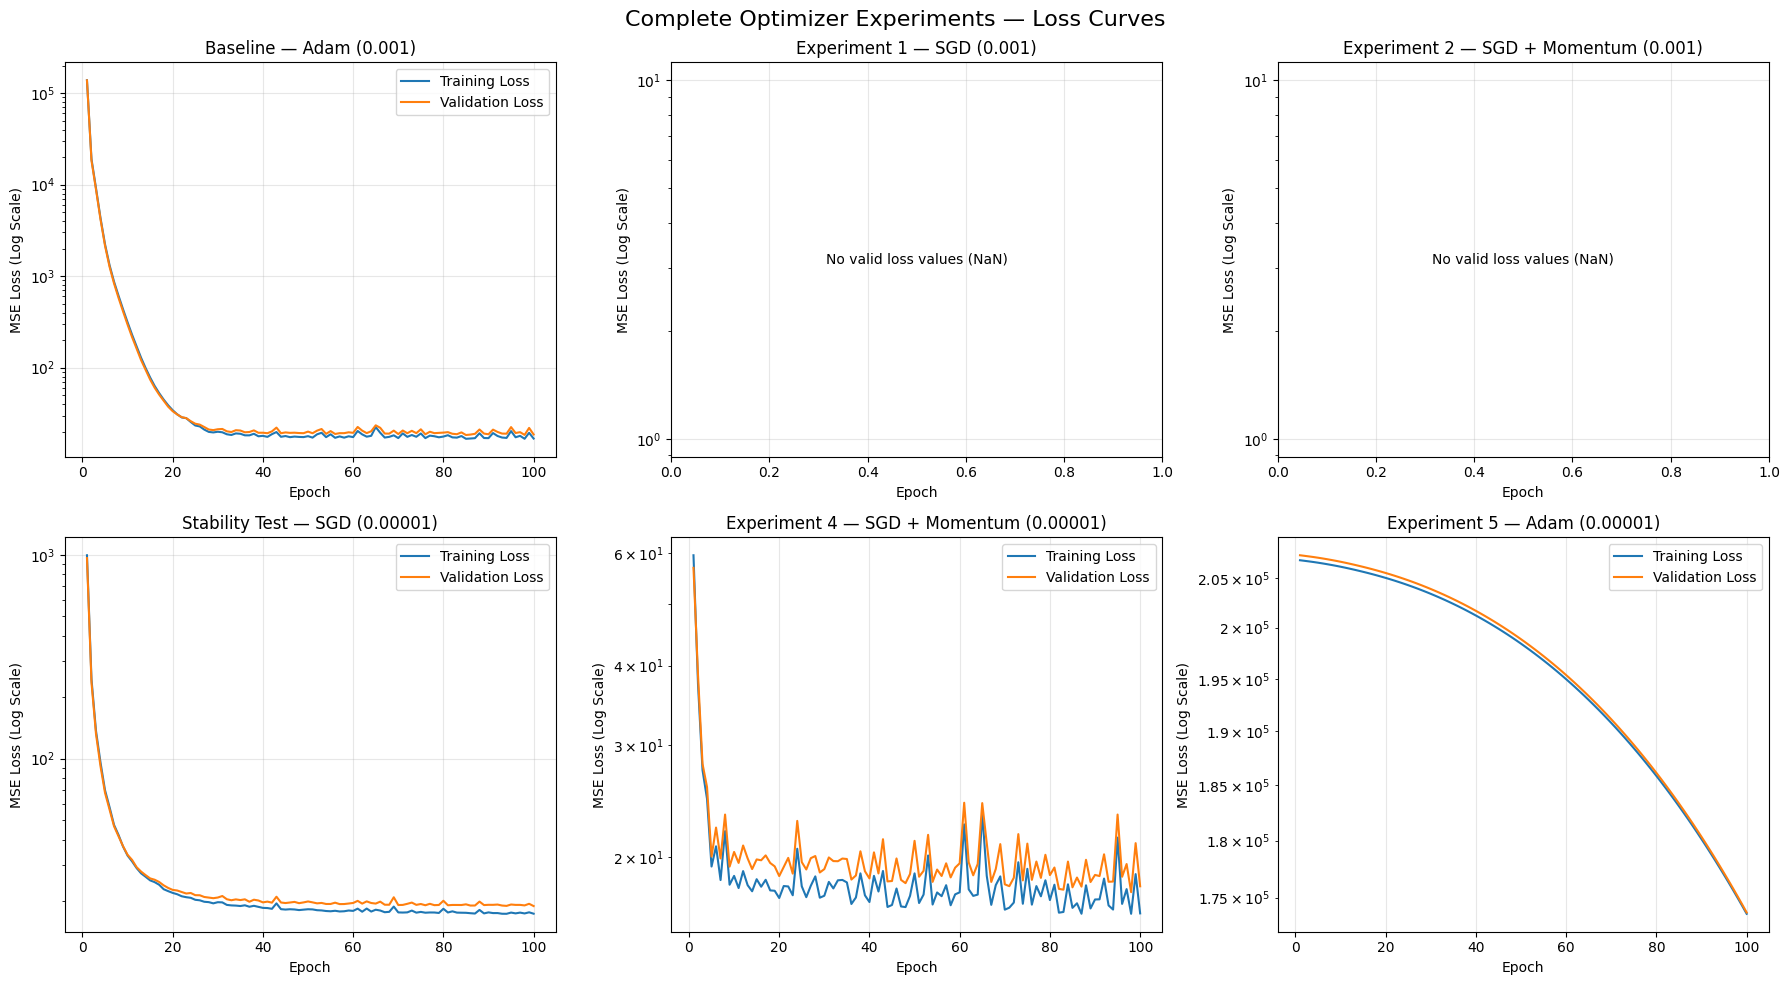

In [57]:

import numpy as np
import matplotlib.pyplot as plt

optimizer_curves = [
    ("Baseline — Adam (0.001)", train_losses, val_losses),
    ("Experiment 1 — SGD (0.001)",
     optimizer_results[0]["Train Losses"],
     optimizer_results[0]["Val Losses"]),
    ("Experiment 2 — SGD + Momentum (0.001)",
     optimizer_results[1]["Train Losses"],
     optimizer_results[1]["Val Losses"]),
    ("Stability Test — SGD (0.00001)",
     sgd_train_losses, sgd_val_losses),
    ("Experiment 4 — SGD + Momentum (0.00001)",
     momentum_train_losses, momentum_val_losses),
    ("Experiment 5 — Adam (0.00001)",
     adam_train_losses, adam_val_losses)
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for ax, (name, train_curve, val_curve) in zip(
    axes, optimizer_curves
):
    train_curve = np.asarray(train_curve, dtype=float)
    val_curve = np.asarray(val_curve, dtype=float)

    train_curve = np.where(
        np.isfinite(train_curve) & (train_curve > 0),
        train_curve, np.nan
    )

    val_curve = np.where(
        np.isfinite(val_curve) & (val_curve > 0),
        val_curve, np.nan
    )

    if np.isfinite(train_curve).any():
        ax.plot(
            np.arange(1, len(train_curve) + 1),
            train_curve,
            label="Training Loss"
        )

    if np.isfinite(val_curve).any():
        ax.plot(
            np.arange(1, len(val_curve) + 1),
            val_curve,
            label="Validation Loss"
        )

    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE Loss (Log Scale)")
    ax.set_yscale("log")
    ax.grid(True, alpha=0.3)

    if np.isfinite(train_curve).any() or np.isfinite(val_curve).any():
        ax.legend()
    else:
        ax.text(
            0.5, 0.5,
            "No valid loss values (NaN)",
            ha="center",
            va="center",
            transform=ax.transAxes
        )

plt.suptitle(
    "Complete Optimizer Experiments — Loss Curves",
    fontsize=16
)
plt.tight_layout()
plt.show()


## <font color="#3B82F6">Batch Size</font>


## <font color="#3B82F6">Depth and Width</font>


## <font color="#3B82F6">Loss Function</font>


# **Experiment Results Table**

# **Loss Curves & Results Analysis**

# **Best Model Selection**


# **Final Test Evaluation**